<h1>IMPORTAÇÃO DE BIBLIOTECAS</h1>

In [1]:
import pandas as pd
import numpy as np

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt


import seaborn as sns

<h2> B) Correlação dos dados - Remoção de Features altamente correlacionadas </h2>

In [2]:
preprocessing_path = "./preprocessing/"

features_dataset_filename = "04-features_dataset.csv"
preprocessing_dataset_fileName = "05-preprocessing_dataset.csv"

df_features_dataset = pd.read_csv(preprocessing_path+features_dataset_filename)

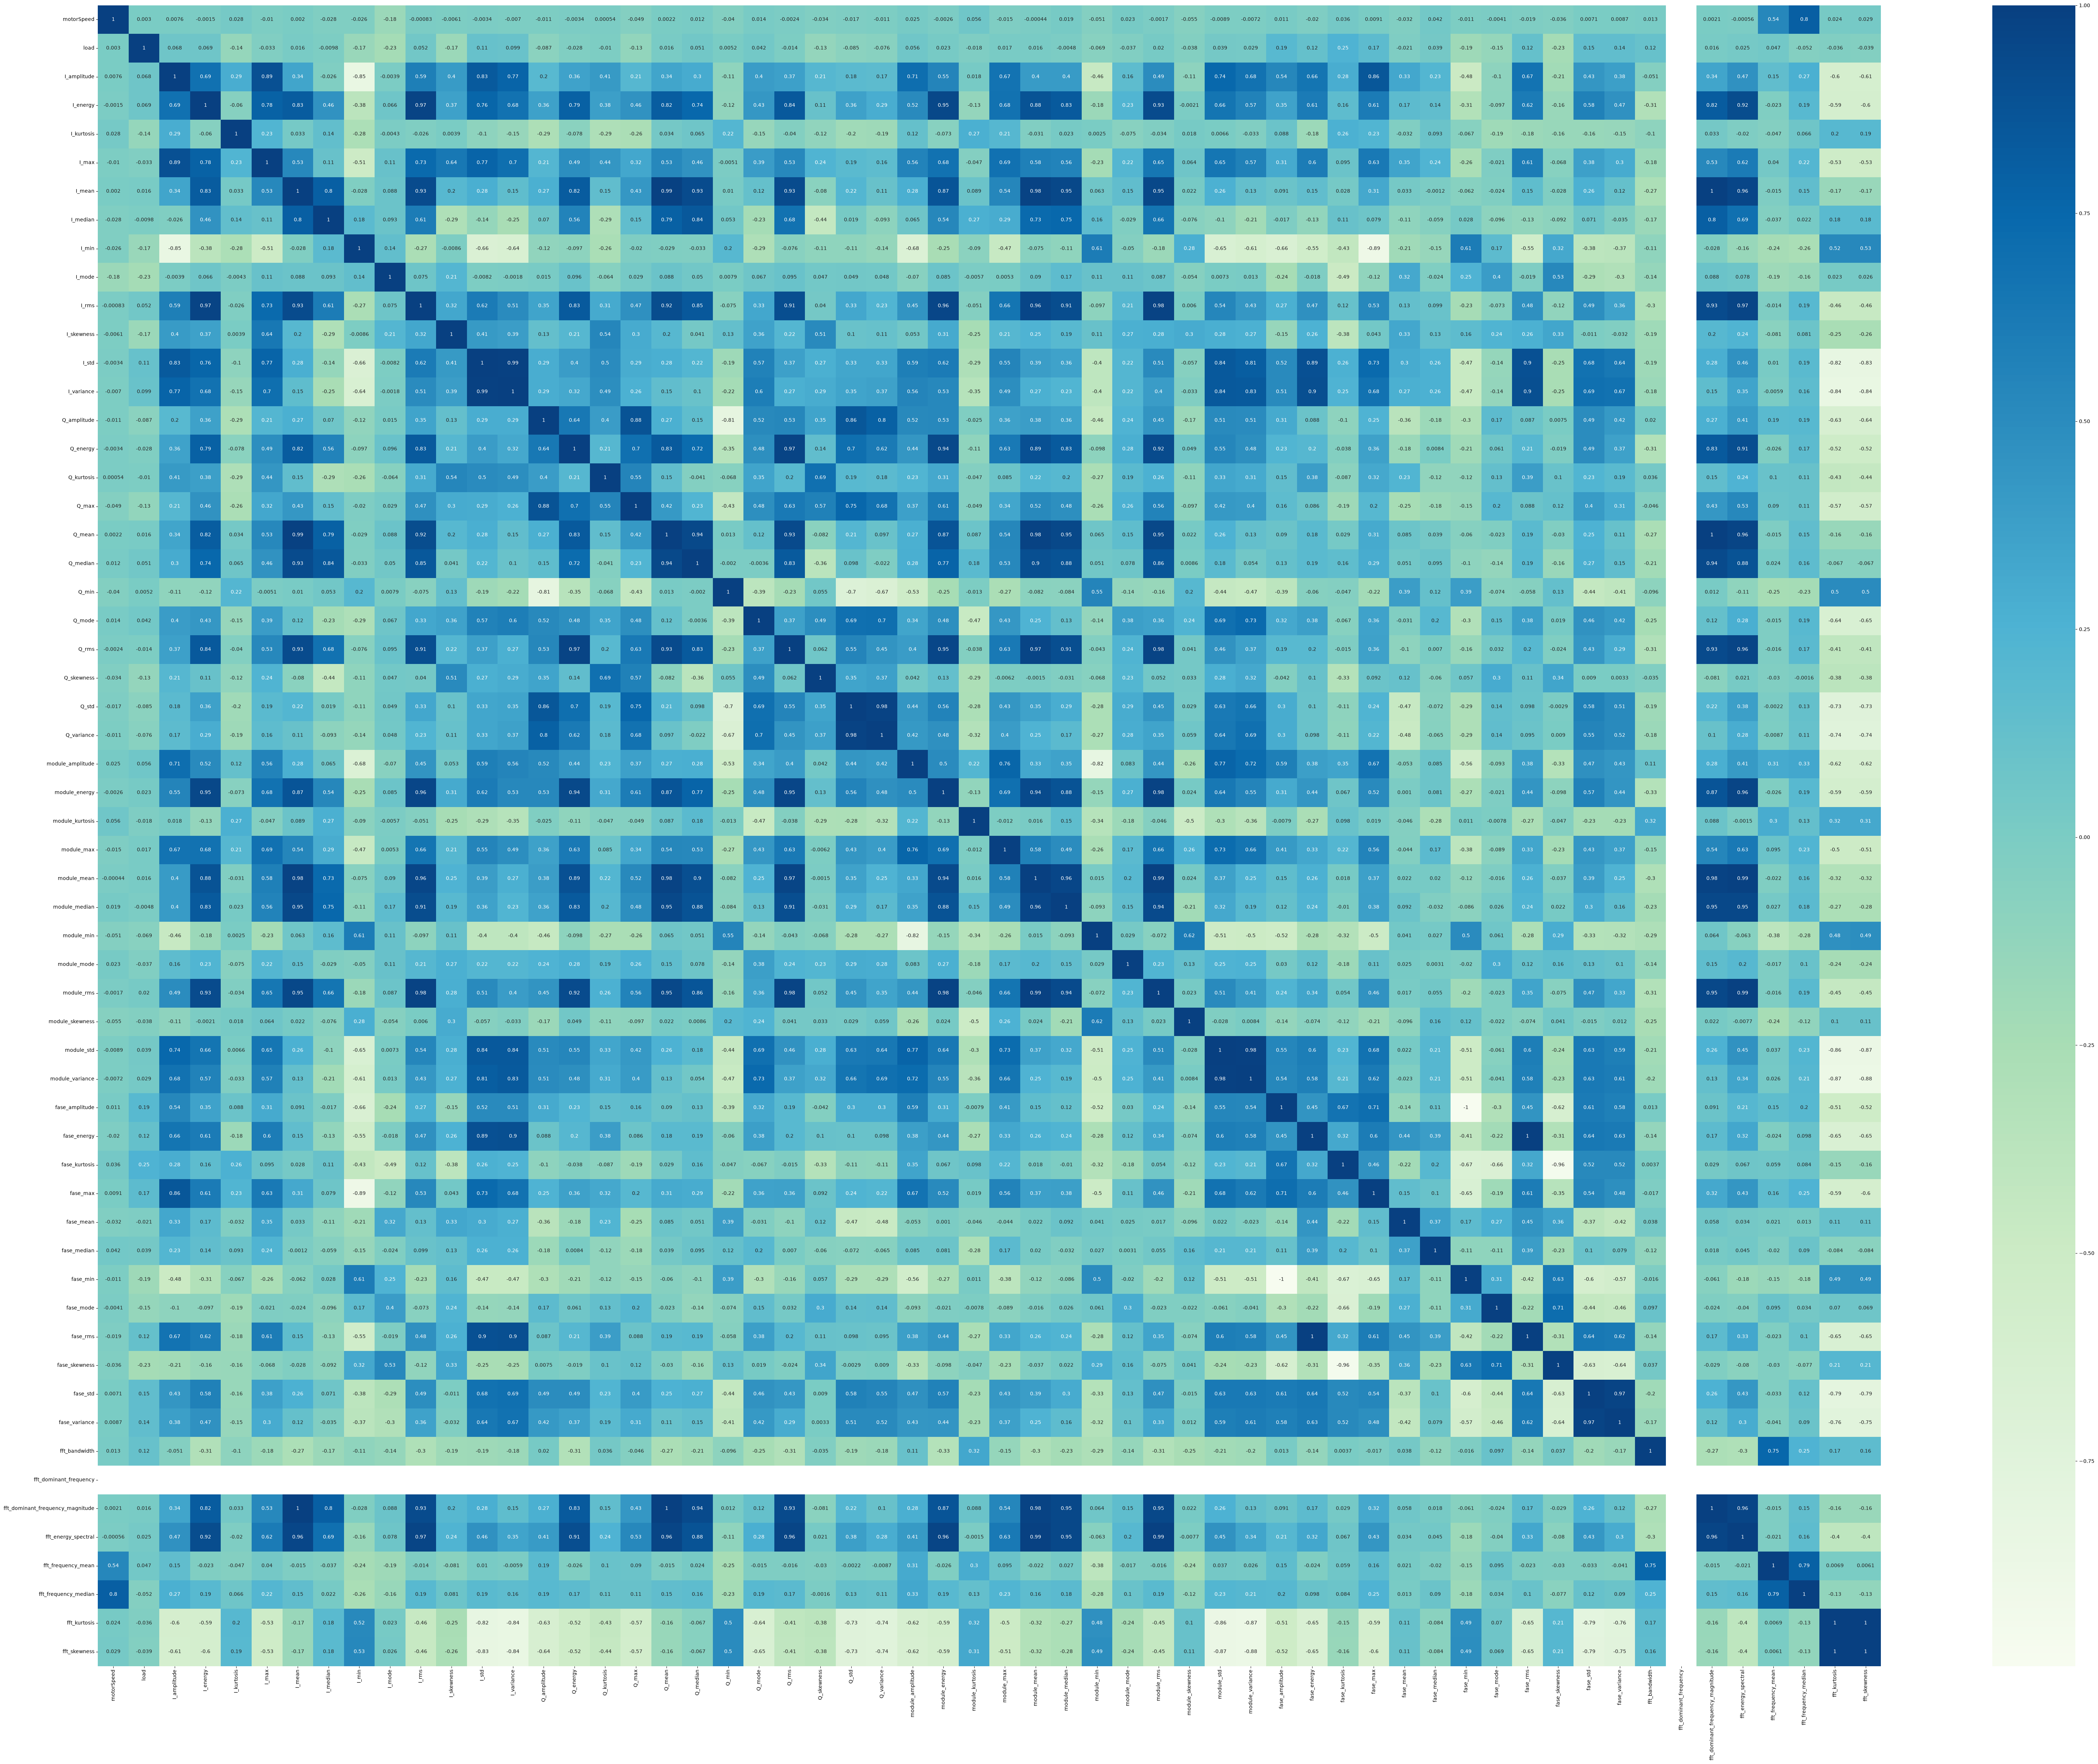

In [3]:
%matplotlib inline

data_numeric = df_features_dataset.select_dtypes(include="number")

def heatmap_corr(data):
    plt.rcParams['figure.figsize'] = [80, 60]
    sns.heatmap(data.corr(),
                annot=True,
                cmap="GnBu"
    )

data_numeric = df_features_dataset.select_dtypes(include="number")
heatmap_corr(data_numeric)

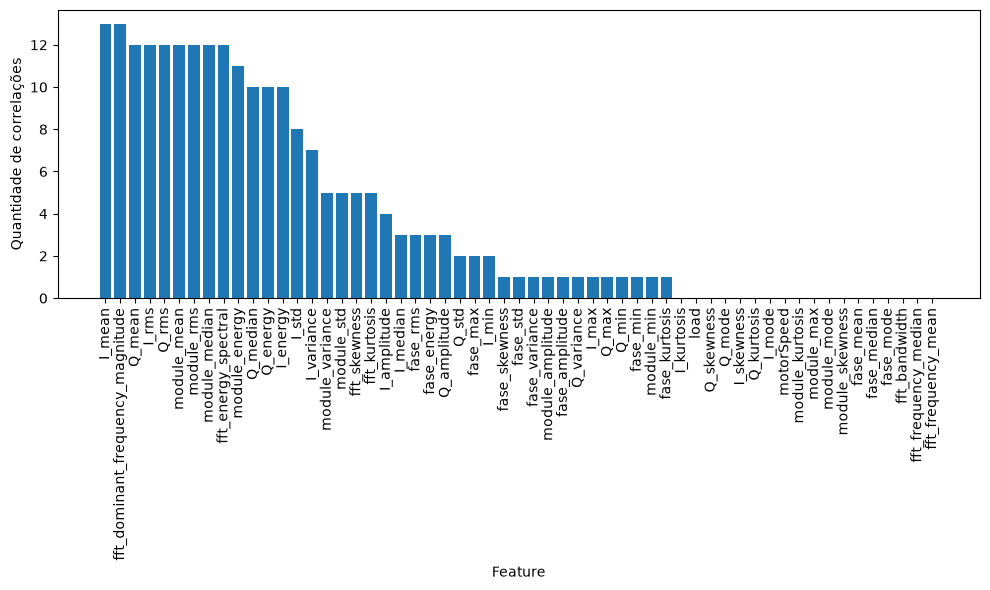

Features removidas:
I_amplitude
I_mean
I_median
I_min
I_rms
I_std
I_variance
Q_amplitude
Q_mean
Q_rms
Q_variance
fase_energy
fase_kurtosis
fase_min
fase_variance
fft_dominant_frequency
fft_dominant_frequency_magnitude
fft_energy_spectral
fft_skewness
module_amplitude
module_energy
module_mean
module_median
module_rms
module_std
module_variance


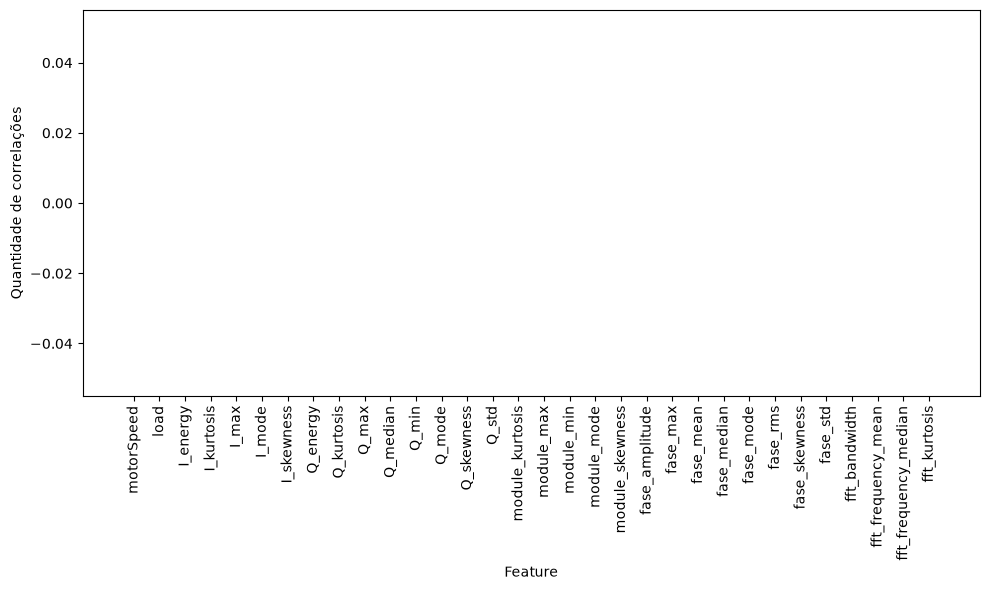

(13830, 35)


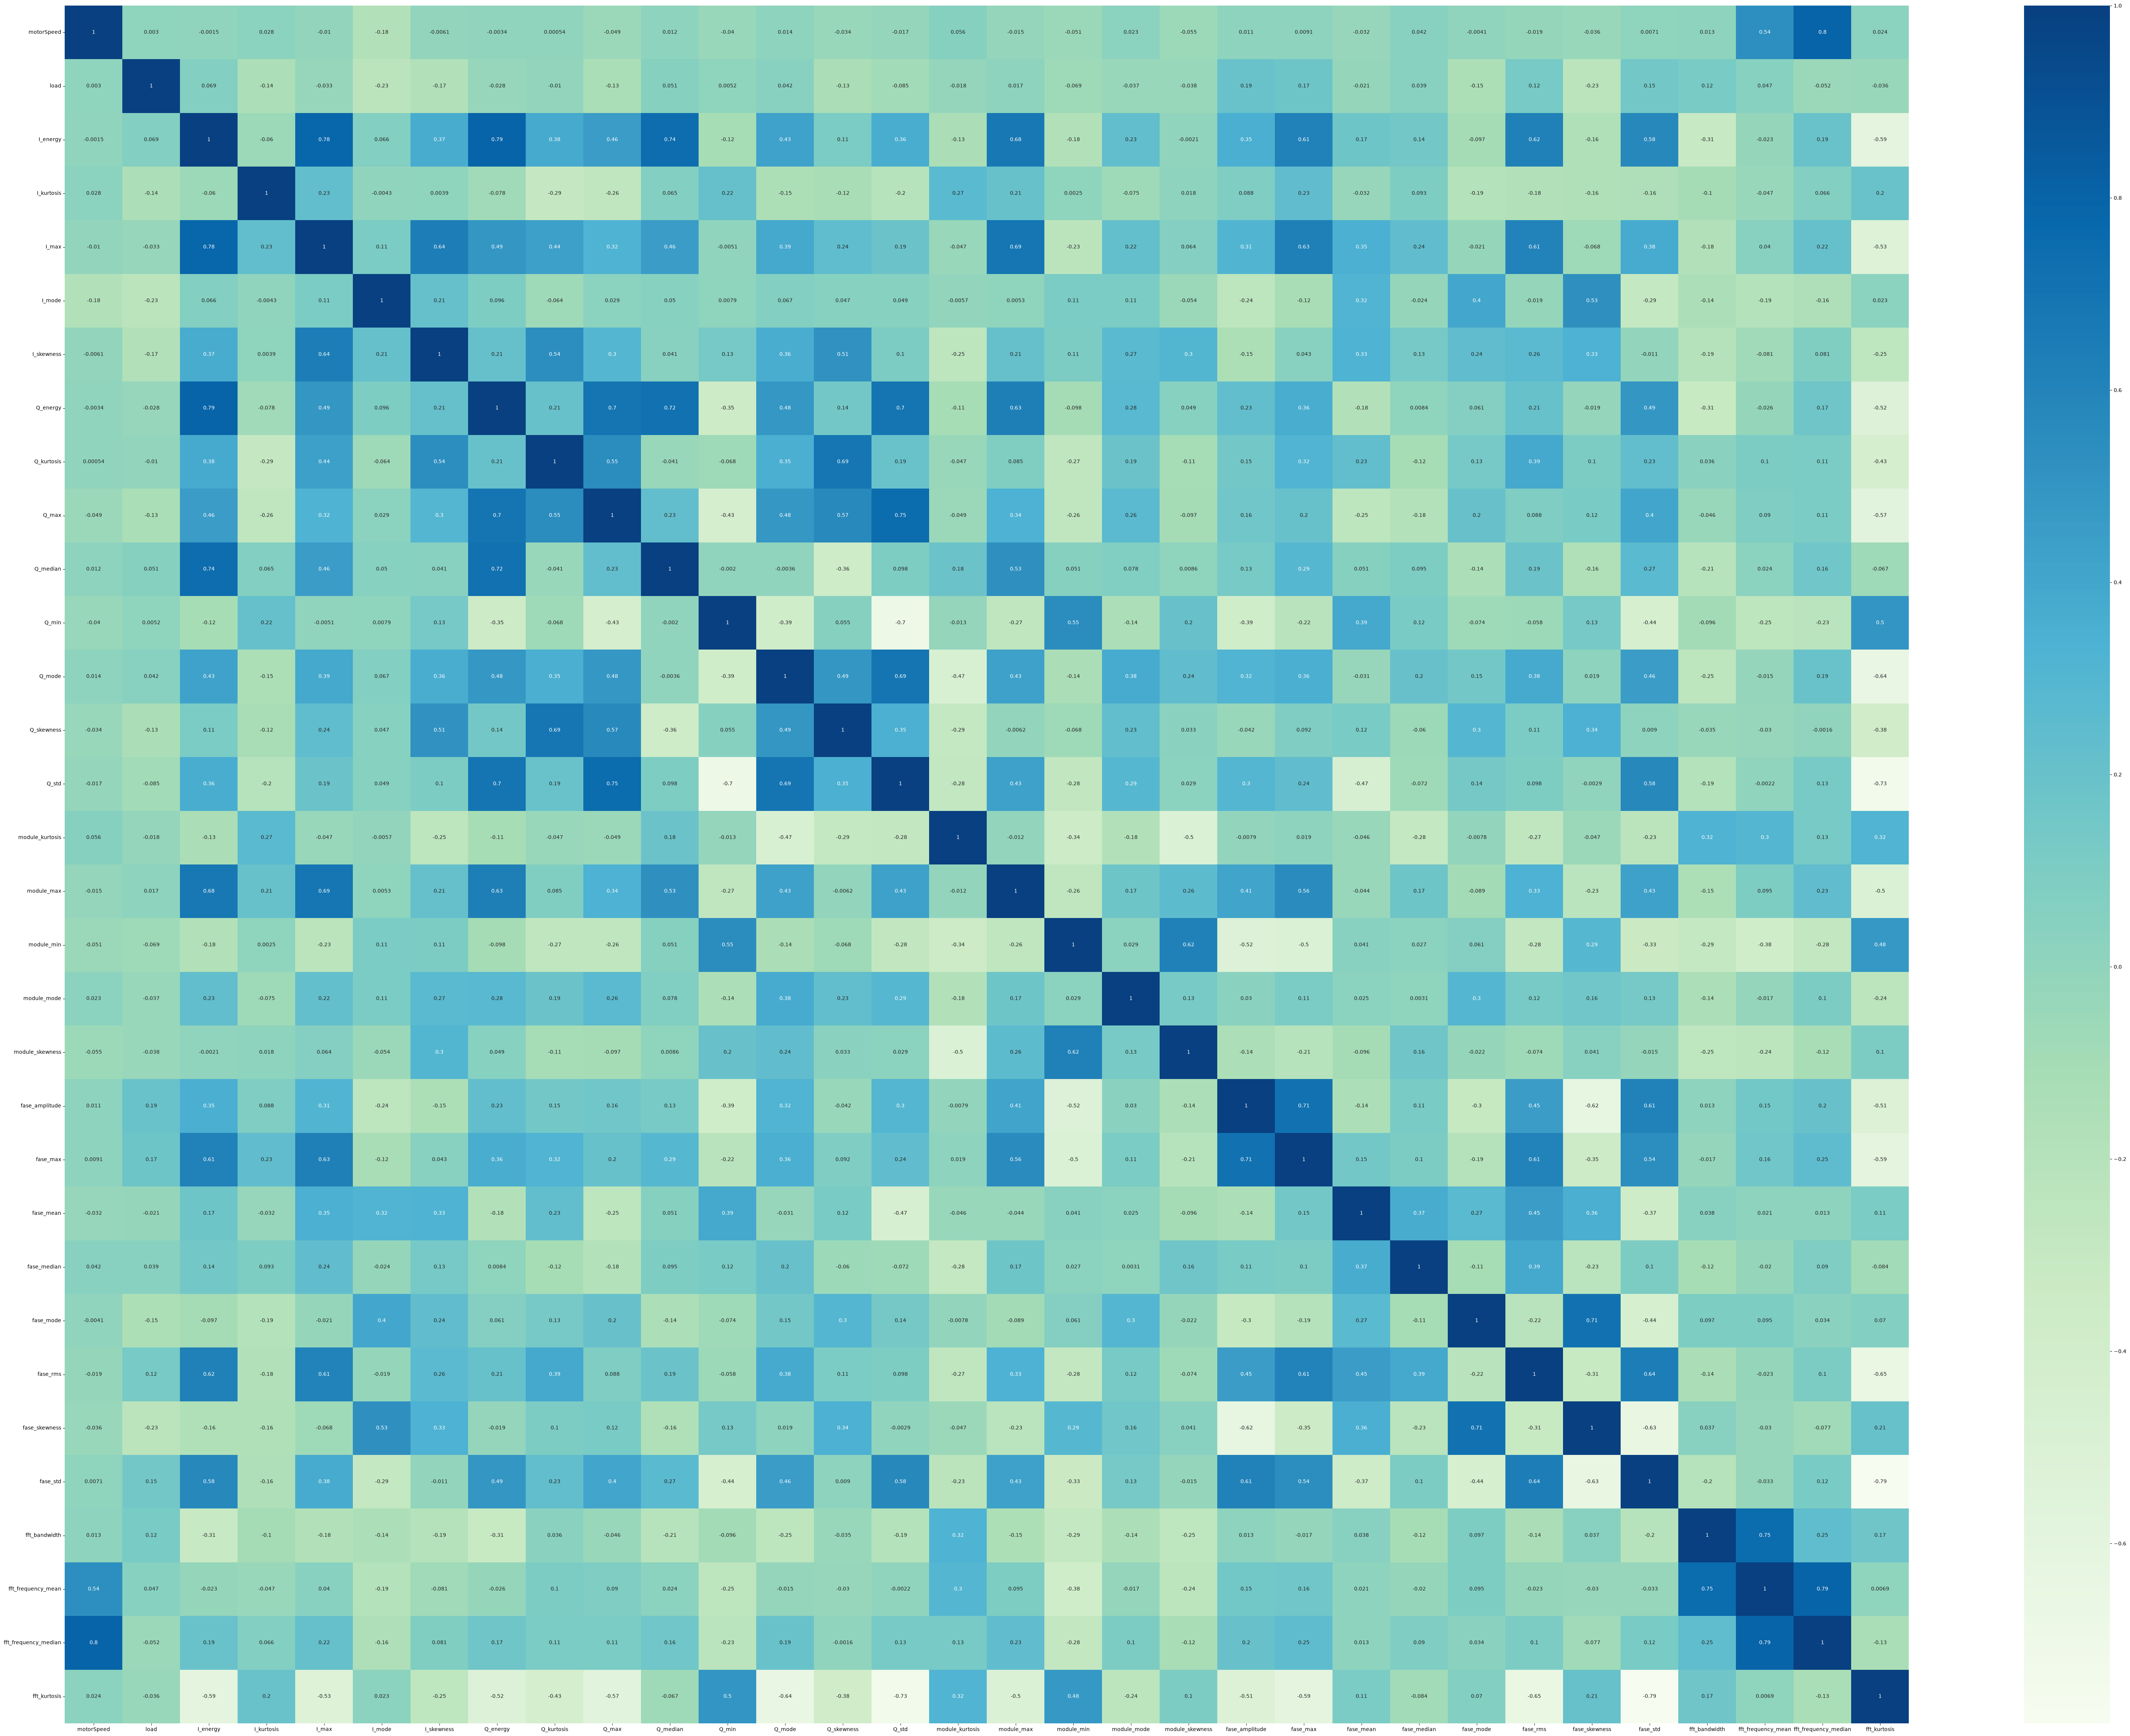

In [4]:
%matplotlib inline

max_high_correlation = 0
hate_high_correlation = 0.8

def count_high_correlation(data):
    mask = np.abs(data) >= hate_high_correlation
    return np.count_nonzero(mask)-1

def max_count_high_correlation(data):
    matriz_corr = data.corr()
    return np.max(matriz_corr.apply(count_high_correlation).sort_values(ascending=False))

def figure_corr(data):
    matriz_corr = data.corr()
    quantity_high_correlation = matriz_corr.apply(count_high_correlation).sort_values(ascending=False)
    plt.figure(figsize=(10, 6))
    plt.bar(quantity_high_correlation.index, quantity_high_correlation.values)
    plt.xticks(rotation=90)
    plt.ylabel("Quantidade de correlações")
    plt.xlabel("Feature")
    plt.tight_layout()
    plt.show()

def drop_high_correlation_feature(data):
    matriz_corr = data.corr()
    quantity_high_correlation = matriz_corr.apply(count_high_correlation).sort_values(ascending=False)
    feature_to_drop = quantity_high_correlation.index[0]
    return feature_to_drop, data.drop(columns=[feature_to_drop])


features_dropped = []

data_numeric_reduzido = data_numeric.copy()

# Retirando features com media e desvio padrão iguais a zero
mask = (data_numeric_reduzido.mean() == 0) & (data_numeric_reduzido.std() == 0)
features_removed = data_numeric_reduzido.columns[mask].tolist()
data_numeric_reduzido = data_numeric_reduzido.drop(columns=features_removed)
features_dropped.extend(features_removed)

# Retirando features com alta correlação
figure_corr(data_numeric_reduzido)

features_removed = []
while max_count_high_correlation(data_numeric_reduzido) > max_high_correlation:
    feature_dropped, data_numeric_reduzido = drop_high_correlation_feature(data_numeric_reduzido)
    features_removed.append(feature_dropped)

features_dropped.extend(features_removed)
print("Features removidas:\n" + '\n'.join(sorted(features_dropped)))

figure_corr(data_numeric_reduzido)
heatmap_corr(data_numeric_reduzido)

df_features_reduzido = df_features_dataset.drop(columns=features_dropped)
print(df_features_reduzido.shape)
df_features_reduzido.to_csv(preprocessing_path+preprocessing_dataset_fileName, index=False)
